In [2]:
import os, sys
sys.path.append('../scripts')

from peak_tester import EmissionsPeakTest
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas_indexing as pix
from pandas_indexing import *
import openpyxl

import joblib

from helper_functions import HiddenPrints, segment_by_peaks, combine_countries, find_peak_in 

In [3]:

def detection_power_curve(
    tester,
    decline_rate,                 # true annual change, Mt/yr (negative for a decline, e.g. -105)
    horizons=range(2, 16),        # window lengths n to test
    n_sims=2000,                  # noise realisations of the TRUE-decline world
    n_bootstrap=2000,             # noise realisations of the NULL world
    alpha=0.05,                   # significance level (false-positive rate)
    null_hypothesis="zero_trend", # "zero_trend", "recent_trend", or a numeric slope
    target_power=0.8,             # horizon is where power first reaches this
    seed=0,                       # tester.noise_generator uses global np.random
    plot=True,
):
    """
    Estimate statistical power vs. window length for detecting a sustained
    linear decline against the tester's fitted noise model.

    For each horizon n:
      - draw n_bootstrap null series (slope = null_trend) + noise  -> null slope distribution
      - draw n_sims signal series (slope = decline_rate) + noise   -> observed slopes
      - p_s = P(null slope <= signal slope_s)   (one-sided: decline = unusually low slope)
      - power(n) = fraction of signal series with p_s < alpha

    Returns a dict with the power curve (DataFrame) and the detection horizon.
    """
    if seed is not None:
        np.random.seed(seed)

    ap = tester.autocorr_params
    use_ar = ap["has_autocorr"] and ap["is_stationary"]

    # Null trend, mirroring run_complete_bootstrap_test
    if null_hypothesis == "zero_trend":
        null_trend = 0.0
    elif null_hypothesis == "recent_trend":
        null_trend = tester.recent_historical_trend
    elif isinstance(null_hypothesis, (int, float)):
        null_trend = float(null_hypothesis)
    else:
        raise ValueError("null_hypothesis must be 'zero_trend', 'recent_trend', or a number")

    def noise_matrix(m, n):
        """m noise realisations of length n, drawn like the bootstrap test does."""
        out = np.empty((m, n))
        for i in range(m):
            out[i] = tester.noise_generator(n, initial_value=None) if use_ar \
                     else tester.noise_generator(n)
        return out

    def slopes(Y, x):
        """OLS slope of each row of Y against x (level-invariant)."""
        xc = x - x.mean()
        Yc = Y - Y.mean(axis=1, keepdims=True)
        return (Yc @ xc) / (xc ** 2).sum()

    records = []
    for n in horizons:
        x = np.arange(n)

        # Null world: slope = null_trend (+ noise). Level omitted; slope is level-invariant.
        null_Y = null_trend * x + noise_matrix(n_bootstrap, n)
        null_slopes = np.sort(slopes(null_Y, x))

        # True-decline world: slope = decline_rate (+ noise)
        sig_Y = decline_rate * x + noise_matrix(n_sims, n)
        sig_slopes = slopes(sig_Y, x)

        # One-sided p-value per realisation: how often the null is at least as low
        ranks = np.searchsorted(null_slopes, sig_slopes, side="right")
        p_values = ranks / len(null_slopes)
        power = float(np.mean(p_values < alpha))

        records.append({"horizon": n, "power": power,
                        "median_p": float(np.median(p_values))})

    power_df = pd.DataFrame(records).set_index("horizon")

    # Detection horizon: first n reaching target power
    reached = power_df.index[power_df["power"] >= target_power]
    detection_horizon = int(reached.min()) if len(reached) else None

    if plot:
        fig, ax = plt.subplots(figsize=(6, 4))
        ax.plot(power_df.index, power_df["power"], marker="o", color="#1D9E75")
        ax.axhline(target_power, color="grey", ls="--", lw=0.8,
                   label=f"target power = {target_power}")
        ax.axhline(alpha, color="grey", ls=":", lw=0.8,
                   label=f"α = {alpha}")
        if detection_horizon is not None:
            ax.axvline(detection_horizon, color="#D85A30", ls="--", lw=1.0,
                       label=f"detection horizon = {detection_horizon} yr")
        ax.set_xlabel("Window length (years of sustained decline)")
        ax.set_ylabel("Power (P(detect | decline is real))")
        ax.set_ylim(0, 1.02)
        ax.set_title(f"Detection power — decline {decline_rate:+.0f} {tester.unit}, "
                     f"σ≈{ap['sigma_residuals']:.0f}, φ≈{ap['phi']:.2f}")
        ax.legend(fontsize=8, framealpha=0.5)
        ax.grid(alpha=0.3)
        plt.tight_layout()

    return {"power": power_df,
            "detection_horizon": detection_horizon,
            "null_trend": null_trend}

In [4]:
# slope tester for World with new Edgar CO2 energy data
slope_testers_co2energy = joblib.load(
    '../outputs/data/edgar_analysis/co2_energy_growing_window_slope_new.joblib'
)
seq_testers_co2energy = joblib.load(
    '../outputs/data/edgar_analysis/co2_energy_growing_window_sequential_new.joblib'
)
co2_energy_expanding_window_slope = pd.read_csv(
    '../outputs/data/edgar_analysis/co2_energy_growing_window_slope_new.csv',
    index_col=0
)
co2_energy_expanding_window_sequential = pd.read_csv(
    '../outputs/data/edgar_analysis/co2_energy_growing_window_sequential_new.csv',
    index_col=0
)

Using AR(1) noise generator with φ=0.47, mean=-0.000, sigma=62.175
Using AR(1) noise generator with φ=0.54, mean=0.000, sigma=140.496
Using white noise generator with mean=0,  σ=9.372
Using white noise generator with mean=0,  σ=107.222
Using AR(1) noise generator with φ=0.62, mean=-0.000, sigma=5.153
Using AR(1) noise generator with φ=0.41, mean=-0.000, sigma=4.865
Using white noise generator with mean=0,  σ=8.061
Using white noise generator with mean=0,  σ=10.828
Using AR(1) noise generator with φ=0.44, mean=-0.000, sigma=50.155
Using AR(1) noise generator with φ=0.49, mean=0.000, sigma=24.146
Using AR(1) noise generator with φ=0.31, mean=0.000, sigma=11.884
Using white noise generator with mean=0,  σ=36.562
Using AR(1) noise generator with φ=0.48, mean=0.000, sigma=8.707
Using AR(1) noise generator with φ=0.43, mean=0.000, sigma=15.500
Using AR(1) noise generator with φ=0.34, mean=-0.000, sigma=10.280
Using white noise generator with mean=0,  σ=11.973
Using AR(1) noise generator with

In [27]:
tester = EmissionsPeakTest()
tester.load_historical_data('projections_upside.csv', region = 'WLD', variable = 'Emissions|CO2|Energy',
                            year_range = range(2000, 2030))
(tester.historical_data.loc[2029] - tester.historical_data.loc[2025])/4

Loaded historical data: 2000-2029
Data points: 30


emissions   -105.551055
dtype: float64

         power  median_p
horizon                 
2        0.066     0.386
3        0.083     0.335
4        0.114     0.268
5        0.184     0.210
6        0.270     0.130
7        0.376     0.085
8        0.514     0.046
9        0.654     0.026
10       0.812     0.018
11       0.868     0.008
12       0.928     0.002
13       0.978     0.002
14       0.987     0.000
15       0.992     0.000
Detection horizon (80% power): 10 years


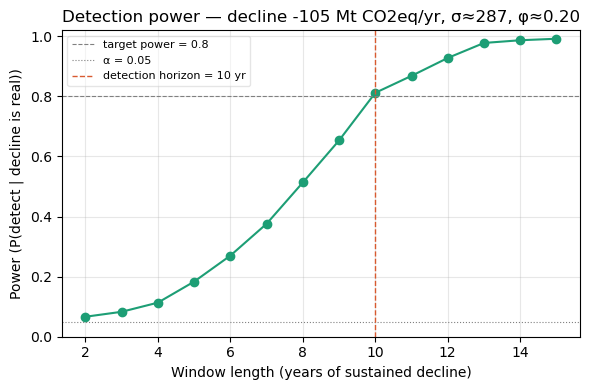

In [5]:
res = detection_power_curve(
    tester=slope_testers_co2energy["WLD"],   # or whichever tester holds the fitted World noise
    decline_rate=-105,                      # Mt/yr scenario decline
    horizons=range(2, 16),
    target_power=0.8,
)
print(res["power"].round(3))
print("Detection horizon (80% power):", res["detection_horizon"], "years")